# Assignment 2: Creating Visualizations with Matplotlib, Seaborn and Plotly

**Name:** MISTHI GUPTA  
**Roll Number:** 2503203100074



## Setup and datasets


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from IPython.display import display

sns.set_theme(style="whitegrid")
tips = px.data.tips()
iris = px.data.iris()
stocks = px.data.stocks()
display(tips.head())

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


## Part A: Matplotlib
### Task 1: Line chart

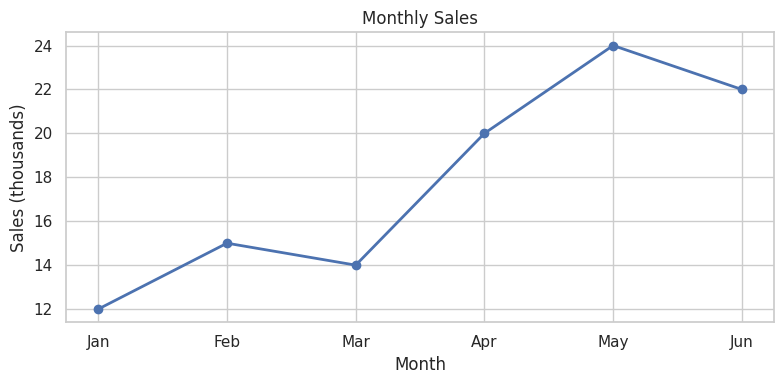

In [2]:
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
sales = [12, 15, 14, 20, 24, 22]  # thousands
plt.figure(figsize=(8, 4))
plt.plot(months, sales, marker="o", linewidth=2)
plt.title("Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Sales (thousands)")
plt.grid(True)
plt.tight_layout()
plt.show()

**Answer:** May had the highest sales, at 24 thousand.

### Task 2: Bar chart

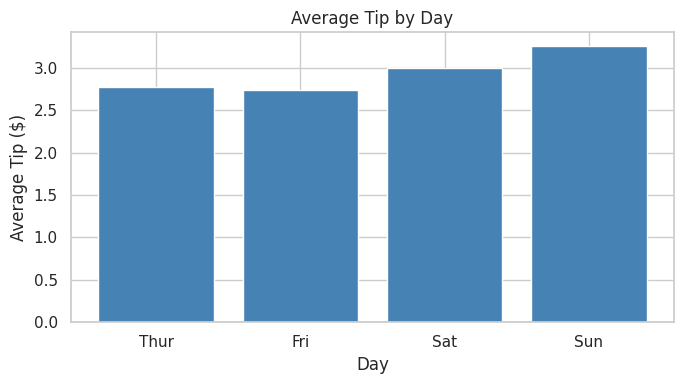

day
Thur    2.77
Fri     2.73
Sat     2.99
Sun     3.26
Name: tip, dtype: float64


In [3]:
day_order = ["Thur", "Fri", "Sat", "Sun"]
avg_tip = tips.groupby("day")["tip"].mean().reindex(day_order)
plt.figure(figsize=(7, 4))
plt.bar(avg_tip.index, avg_tip.values, color="steelblue")
plt.title("Average Tip by Day")
plt.xlabel("Day")
plt.ylabel("Average Tip ($)")
plt.tight_layout()
plt.show()
print(avg_tip.round(2))

**Answer:** Sunday has the highest average tip (approximately $3.26).

### Task 3: Histogram and scatter plot side by side

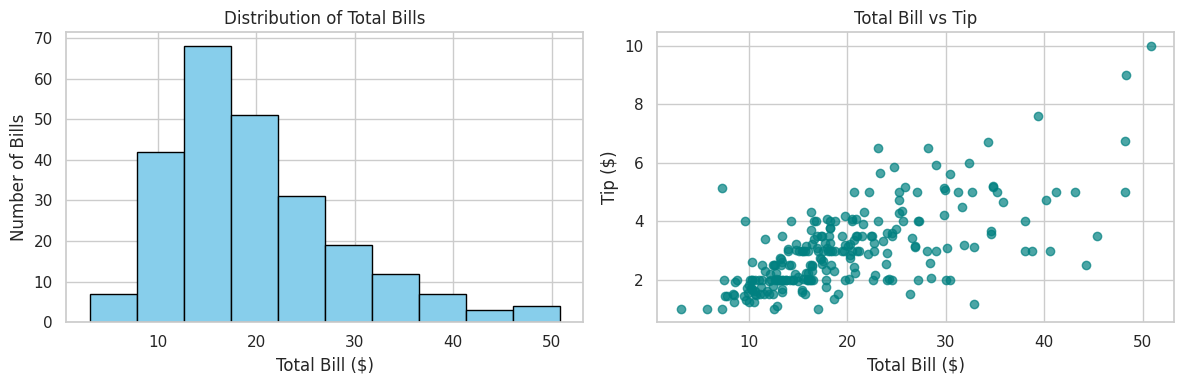

Saved tips_plots.png in the notebook working directory.


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(tips["total_bill"], bins=10, color="skyblue", edgecolor="black")
axes[0].set_title("Distribution of Total Bills")
axes[0].set_xlabel("Total Bill ($)")
axes[0].set_ylabel("Number of Bills")
axes[1].scatter(tips["total_bill"], tips["tip"], alpha=0.7, color="teal")
axes[1].set_title("Total Bill vs Tip")
axes[1].set_xlabel("Total Bill ($)")
axes[1].set_ylabel("Tip ($)")
plt.tight_layout()
plt.savefig("tips_plots.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved tips_plots.png in the notebook working directory.")

**Answer:** Most restaurant bills fall roughly between $10 and $25.  
In general, tips tend to increase as the total bill increases, although the points vary.

## Part B: Seaborn
### Task 4: Count plot and bar plot

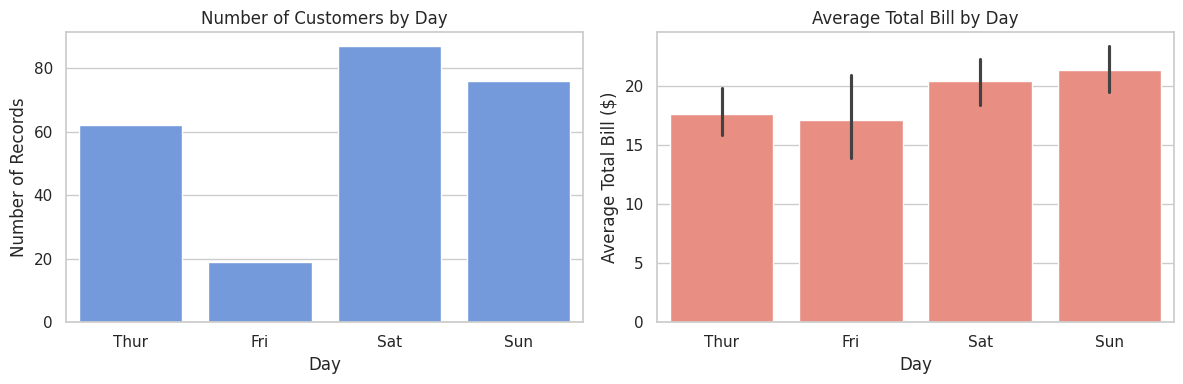

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=tips, x="day", order=day_order, ax=axes[0], color="cornflowerblue")
axes[0].set_title("Number of Customers by Day")
axes[0].set_xlabel("Day")
axes[0].set_ylabel("Number of Records")
sns.barplot(data=tips, x="day", y="total_bill", order=day_order, ax=axes[1], color="salmon")
axes[1].set_title("Average Total Bill by Day")
axes[1].set_xlabel("Day")
axes[1].set_ylabel("Average Total Bill ($)")
plt.tight_layout()
plt.show()

**Answer:** Saturday has the most records/customers in this dataset (87). Sunday has the highest average bill (about $21.41).

### Task 5: Box plot

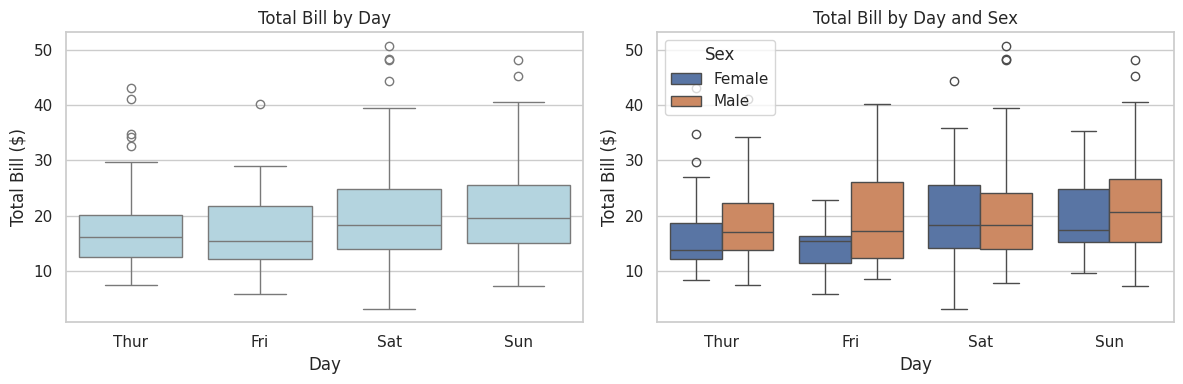

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=tips, x="day", y="total_bill", order=day_order, ax=axes[0], color="lightblue")
axes[0].set_title("Total Bill by Day")
axes[0].set_xlabel("Day")
axes[0].set_ylabel("Total Bill ($)")
sns.boxplot(data=tips, x="day", y="total_bill", hue="sex", order=day_order, ax=axes[1])
axes[1].set_title("Total Bill by Day and Sex")
axes[1].set_xlabel("Day")
axes[1].set_ylabel("Total Bill ($)")
axes[1].legend(title="Sex")
plt.tight_layout()
plt.show()

**Answer:** Sunday has the highest median bill (about $19.63). Dots beyond the whiskers are potential outliers, meaning unusually high or low bills under the box-plot rule. With `hue="sex"`, each day is split into male and female groups, revealing differences in their bill distributions.

### Task 6: Scatter plot with colour and style

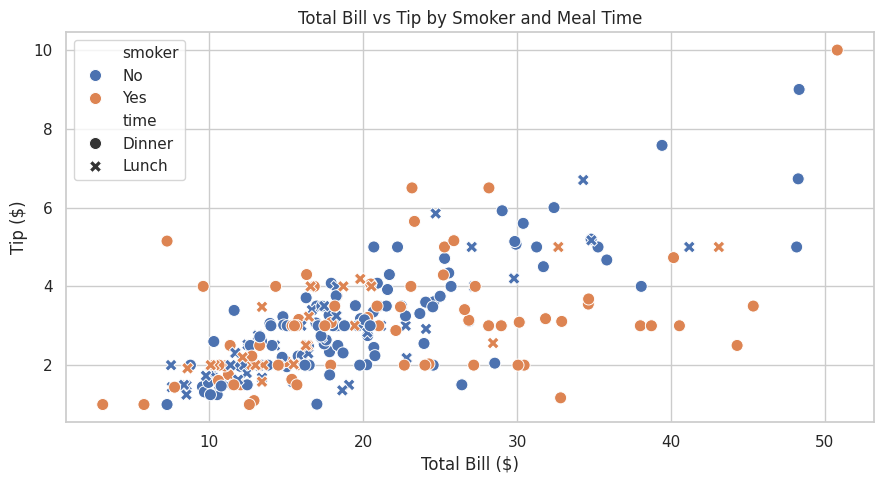

smoker
No     2.99
Yes    3.01
Name: tip, dtype: float64


In [7]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="smoker", style="time", s=75)
plt.title("Total Bill vs Tip by Smoker and Meal Time")
plt.xlabel("Total Bill ($)")
plt.ylabel("Tip ($)")
plt.tight_layout()
plt.show()
print(tips.groupby("smoker")["tip"].mean().round(2))

**Answer:** Smokers and non-smokers show overlapping tipping patterns, so the scatter plot does not show a strong, clear difference in tip amounts.

### Task 7: Pair plot

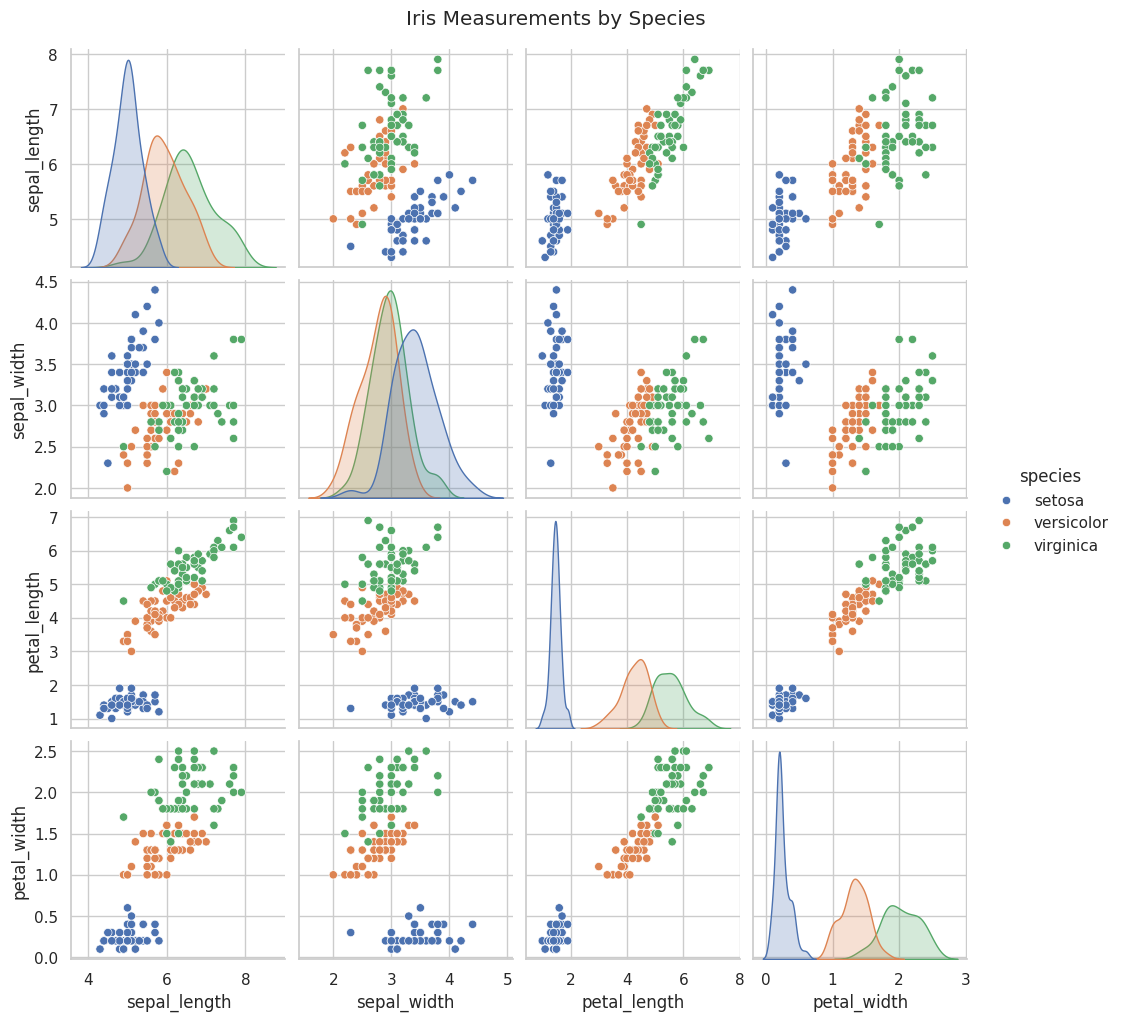

In [8]:
g = sns.pairplot(iris, hue="species", vars=["sepal_length", "sepal_width", "petal_length", "petal_width"])
g.figure.suptitle("Iris Measurements by Species", y=1.02)
plt.show()

**Answer:** Petal length and petal width separate the species most clearly. Setosa is easiest to identify because its petal measurements form a distinct cluster.

## Part C: Plotly
### Task 8: Interactive scatter plot

In [9]:
fig = px.scatter(tips, x="total_bill", y="tip", color="day", size="size",
                 hover_data=["sex", "time"], title="Bill vs Tip")
fig.update_layout(xaxis_title="Total Bill ($)", yaxis_title="Tip ($)")
fig.show()

**Answer:** Unlike these static Matplotlib charts, this Plotly chart lets me (1) hover over points to see detailed values and (2) zoom into a selected area or hide a day by clicking its legend entry.

### Task 9: Interactive box plot and histogram

In [10]:
fig = px.box(tips, x="day", y="total_bill", color="sex", title="Bills by Day and Sex")
fig.update_layout(xaxis_title="Day", yaxis_title="Total Bill ($)")
fig.show()
fig = px.histogram(tips, x="total_bill", color="time", nbins=15, title="Total Bill Distribution by Meal")
fig.update_layout(xaxis_title="Total Bill ($)", yaxis_title="Number of Bills")
fig.show()

**Answer:** Dinner generally has larger bills than Lunch. The median bill for Dinner is about $18.39, compared with $15.97 for Lunch.

### Task 10: Line chart with range slider

In [11]:
fig = px.line(stocks, x="date", y=["GOOG", "AAPL", "AMZN"], title="Stock Prices Relative to Starting Week")
fig.update_layout(xaxis_title="Date", yaxis_title="Relative Stock Price (start = 1.0)", legend_title="Company")
fig.update_xaxes(rangeslider_visible=True)
fig.show()
print("Last available observations:")
print(stocks[["date", "GOOG", "AAPL", "AMZN"]].tail(1).to_string(index=False))

Last available observations:
      date     GOOG  AAPL    AMZN
2019-12-30 1.213014 1.678 1.50336


**Answer:** AAPL (Apple) grew the most by the end of 2019 among these three stocks. For a three-month period, selecting July–September 2019 with the slider shows fluctuations rather than uninterrupted growth; the lines rise and fall over the selected weeks. *(You can select this period yourself using the range slider.)*

## Part D: Comparing the Libraries
### Task 11: Comparison table

| Feature | Matplotlib | Seaborn | Plotly |
|---|---|---|---|
| Ease of use | Medium | Easy | Easy |
| Interactive charts? | No (these examples are static) | No (these examples are static) | Yes |
| Best used for | Detailed static charts and lab reports | Quick statistical visualizations | Interactive dashboards and web pages |

**Answer:** For a lab report, I would choose Matplotlib because it provides precise control over static figures and is easy to export as an image. For a web page, I would choose Plotly because users can hover, zoom, and interact with the charts.

## Submission checklist

- [ ] Replace the name and roll number at the top.
- [ ] Run all cells from the top using **Restart Kernel and Run All**.
- [ ] Confirm the charts are visible, including Plotly charts (rendering may vary by notebook viewer).
- [ ] Submit this notebook renamed to `RollNo_Name_Assignment2.ipynb`.
- [ ] Submit `tips_plots.png` created in Task 3 separately.
- [ ] Review and rewrite answers in your own words, as required by the assignment.